# Part III — k-means: the three families of cars
**Method (sessions 10–11):** k-means clustering, elbow plot and silhouette score.
**Why:** the professor noted that *"some teams simply have better cars"*. We describe each car with two simple team statistics:
- **car performance** = the team's points per race over its last 5 races,
- **reliability** = minus the team's mechanical-failure rate over its last 10 races,

both standardised (mean 0, standard deviation 1). On this map, cars form groups; k-means finds them automatically, and the group becomes a feature: **top car / midfield car / unreliable car**.

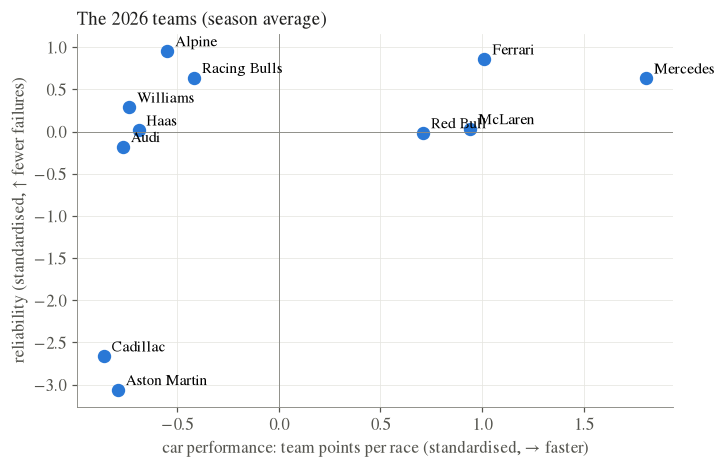

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1duel.data import build, TEAM_STATS
from f1duel.plots import style, title, save, BLUE, ORANGE, AQUA, GREY, INK, INK2, MUTED, TIER_COLORS
style(); pd.set_option('display.width', 140); pd.set_option('display.max_columns', 20)
d = build()
from f1duel.model import CarProfile
prof = CarProfile().fit(d[d.year <= 2024])
dd = prof.transform(d)
season = dd[dd.year == 2026].groupby('team_name')[['car_perf', 'car_rel']].mean()
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.scatter(season.car_perf, season.car_rel, s=60, color=BLUE)
for t, r in season.iterrows(): ax.annotate(t, (r.car_perf, r.car_rel), xytext=(5, 3), textcoords='offset points', fontsize=10)
ax.axhline(0, color=MUTED, lw=0.6); ax.axvline(0, color=MUTED, lw=0.6)
ax.set_xlabel('car performance: team points per race (standardised, → faster)'); ax.set_ylabel('reliability (standardised, ↑ fewer failures)')
title(ax, 'The 2026 teams (season average)'); save(fig, '03_map_2026'); plt.show()

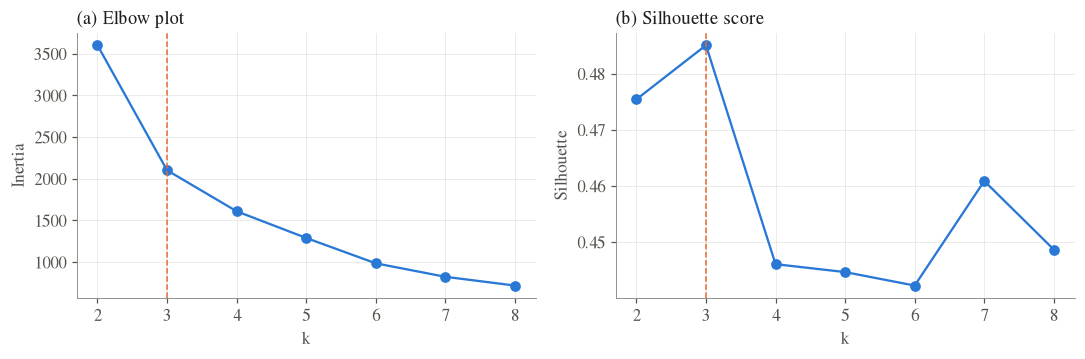

k,2,3,4,5,6,7,8
inertia,3601.000,2101.000,1610.000,1289.000,985.000,824.000,718.000
silhouette,0.475,0.485,0.446,0.445,0.442,0.461,0.449


In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
train = d[d.year <= 2024]
prof = CarProfile().fit(train)
Z = prof._z(train.drop_duplicates(['raceId', 'team']))
ks = range(2, 9); inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=20, random_state=2026).fit(Z); inertia.append(km.inertia_); sil.append(silhouette_score(Z, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(ks, inertia, 'o-', color=BLUE); ax[0].set_xlabel('k'); ax[0].set_ylabel('Inertia'); title(ax[0], '(a) Elbow plot')
ax[1].plot(ks, sil, 'o-', color=BLUE); ax[1].set_xlabel('k'); ax[1].set_ylabel('Silhouette'); title(ax[1], '(b) Silhouette score')
for a in ax: a.axvline(3, color=ORANGE, ls='--', lw=1)
fig.tight_layout(); save(fig, '03_choose_k'); plt.show()
pd.DataFrame({'k': list(ks), 'inertia': np.round(inertia), 'silhouette': np.round(sil, 3)}).set_index('k').T

**Choice: k = 3.** The elbow bends at 3 and the silhouette score is highest at k = 3: both criteria agree.

In [3]:
dd = prof.transform(d)
summary = dd.groupby('tier').agg(starts=('top10', 'size'), scored=('top10', 'mean'), podium=('podium', 'mean'),
                                 avg_grid=('grid', 'mean'), car_perf=('car_perf', 'mean'))
summary.index = ['Top car', 'Midfield car', 'Unreliable car']; summary.round(2)

,starts,scored,podium,avg_grid,car_perf
Top car,2003,0.83,0.43,5.26,1.41
Midfield car,3665,0.37,0.03,12.73,-0.51
Unreliable car,1563,0.28,0.03,14.69,-0.60


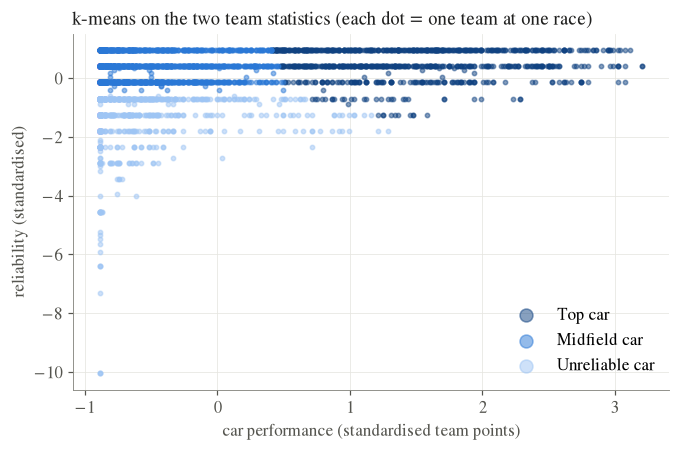

In [4]:
pts = dd[dd.year <= 2024].drop_duplicates(['raceId', 'team'])
fig, ax = plt.subplots(figsize=(7, 4.2))
for t, name in enumerate(['Top car', 'Midfield car', 'Unreliable car']):
    p = pts[pts.tier == t]; ax.scatter(p.car_perf, p.car_rel, s=8, alpha=0.5, color=TIER_COLORS[t], label=name)
ax.set_xlabel('car performance (standardised team points)'); ax.set_ylabel('reliability (standardised)'); ax.legend(markerscale=3)
title(ax, 'k-means on the two team statistics (each dot = one team at one race)'); save(fig, '03_clusters'); plt.show()

**Reading:** the three families are not simply fast / medium / slow. A **top car** (high points, few failures) scores in about 83% of its starts. The two others score about as many points per race, but differ in reliability: **midfield cars** break down in about 5% of races and score in 37% of their starts, **unreliable cars** break down in about 22% and score in 28%. In 2026, Aston Martin (new Honda engine) and Cadillac (new team) are unreliable cars. In Part IV, these groups help the model see a fast car stuck at the back of the grid, or a car likely to break down.